# Loudoun carbon-aware scheduler (AI + Climate)
When should a Loudoun data center run a flexible 4-hour job tomorrow? We forecast PJM grid carbon intensity (the grid serving Dominion/Loudoun), pick the cleanest window, and test on all of 2026 (never seen in training). All results below are produced by this notebook.

**Honest scope:** the signal is PJM-wide *average* emissions, not Loudoun-specific and not marginal.

In [1]:
import os, subprocess, sys
if not os.path.exists("src/sweep.py"):
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")
    else:  # Colab
        subprocess.run(["git","clone","https://github.com/Harshal623/clean-hour.git"], check=False)
        os.chdir("clean-hour")
subprocess.run([sys.executable,"-m","pip","install","-q","-r","requirements.txt"], check=False)
def run(script):
    r = subprocess.run([sys.executable,"-W","ignore",script], capture_output=True, text=True)
    print(r.stdout[-9000:])
    if r.returncode:
        print('STDERR:', r.stderr[-2000:])
print(os.getcwd())

C:\Users\Harsh\Downloads\hackathon 1\carbon


## 1. Data (downloads EIA-930 + Open-Meteo on first run; cached afterwards)

In [2]:
run("src/load_data.py")

(33936, 12) 2023-01-01 06:00:00 -> 2026-11-15 05:00:00
missing share per column:
 coal           0.001
gas            0.001
nuclear        0.001
oil            0.001
hydro          0.001
solar          0.001
wind           0.001
other          0.001
unknown        1.000
demand         0.001
demand_fcst    0.004
dom_demand     0.007
carbon intensity gCO2/kWh: {'count': 33908.0, 'mean': 345.5, 'std': 34.0, 'min': 223.6, '25%': 321.5, '50%': 342.9, '75%': 368.4, 'max': 440.2}
weather (33888, 5) 2023-01-01 01:00:00 -> 2026-11-13 00:00:00 {'temperature_2m': 0.0, 'relative_humidity_2m': 0.0, 'wind_speed_10m': 0.0, 'cloud_cover': 0.0, 'shortwave_radiation': 0.0}



## 2. Schema-change check (EIA renamed fuel columns in mid-2024)
No step change in carbon intensity or fuel shares at the red line.

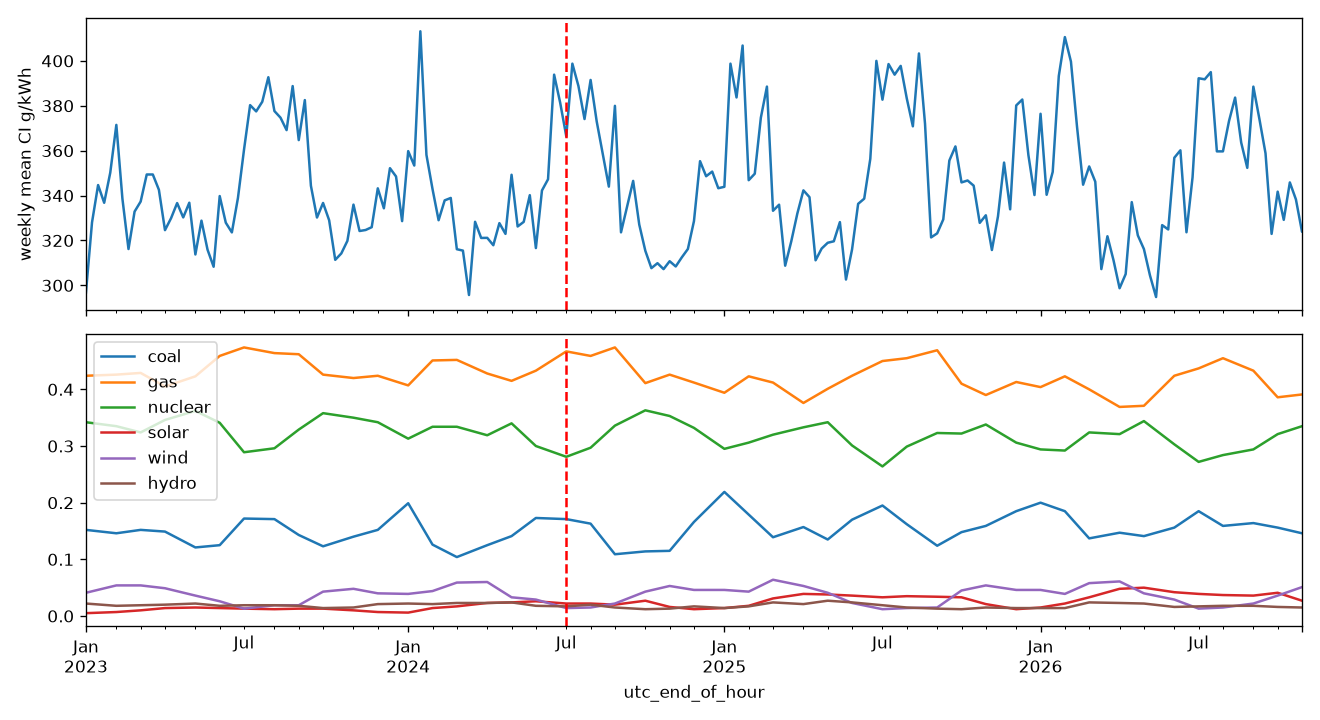

In [3]:
from IPython.display import Image, display
display(Image("results/ci_schema_changeover.png"))

## 3. The deciding test: model vs persistence vs hour-of-week climatology vs perfect foresight
Slip = how many hours the job may be delayed. Train 2023-2025, test 2026, 95% CIs from a 7-day block bootstrap, emission-factor sensitivity at the end.

In [4]:
run("src/sweep.py")

last real EIA hour (UTC): 2026-11-14 05:00:00 | hours: 33912 | truly missing CI hours: 4
train days 1087 | test days kept 311 of 314 (dropped 3 with missing target hours) | test 2026-01-01 -> 2026-11-10
hourly MAE persistence             21.45 | lead<=24h: 17.44
hourly MAE climatology             29.72 | lead<=24h: 29.81
hourly MAE model (full)            13.84 | lead<=24h: 12.82
hourly MAE model (history only)    18.84 | lead<=24h: 15.47

Mean gCO2/kWh of chosen 4h window, TEST (lower = better):
 slip_h  immediate  persistence  climatology  model  model_hist  oracle
      0     353.37       353.37       353.37 353.37      353.37  353.37
     12     353.37       329.81       342.86 330.45      329.15  325.54
     24     353.37       330.61       342.62 330.31      329.49  324.68
     48     353.37       330.61       337.15 323.57      326.44  315.79
     72     353.37       330.61       331.01 318.21      322.81  309.72

% saved vs run-immediately:
 slip_h  persistence_%saved  climatol

## 4. Final analysis: model vs persistence, the 'unsure, run now' rule, three failure days

In [5]:
run("src/final.py")

Model minus PERSISTENCE (g/kWh, negative = model better), block-bootstrap 95% CI
  slip 12h full:  +0.64 [ -0.89, +2.03] better on 28% of days | history-only:  -0.67 [ -1.57, +0.16]
  slip 24h full:  -0.30 [ -1.91, +1.32] better on 35% of days | history-only:  -1.12 [ -2.23, -0.09]
  slip 48h full:  -7.04 [ -9.40, -4.73] better on 53% of days | history-only:  -4.17 [ -5.99, -2.25]
  slip 72h full: -12.40 [-15.35, -9.43] better on 60% of days | history-only:  -7.80 [-10.42, -4.78]

'Unsure, run now' rule. tau tuned on val (2025-07..12), then applied to test.
  slip 24h: tau=0 g/kWh | TEST no-abstain cost 330.31, acts 100% days, worse-than-immediate 8% | with-abstain cost 330.31, acts 100%, worse-than-immediate 8%
  slip 72h: tau=2 g/kWh | TEST no-abstain cost 318.21, acts 100% days, worse-than-immediate 6% | with-abstain cost 318.25, acts 97%, worse-than-immediate 5%

Worst model days at slip 24h (regret = chosen minus best possible window):
   {'day': '2026-02-20', 'regret': 43.1, 'mod

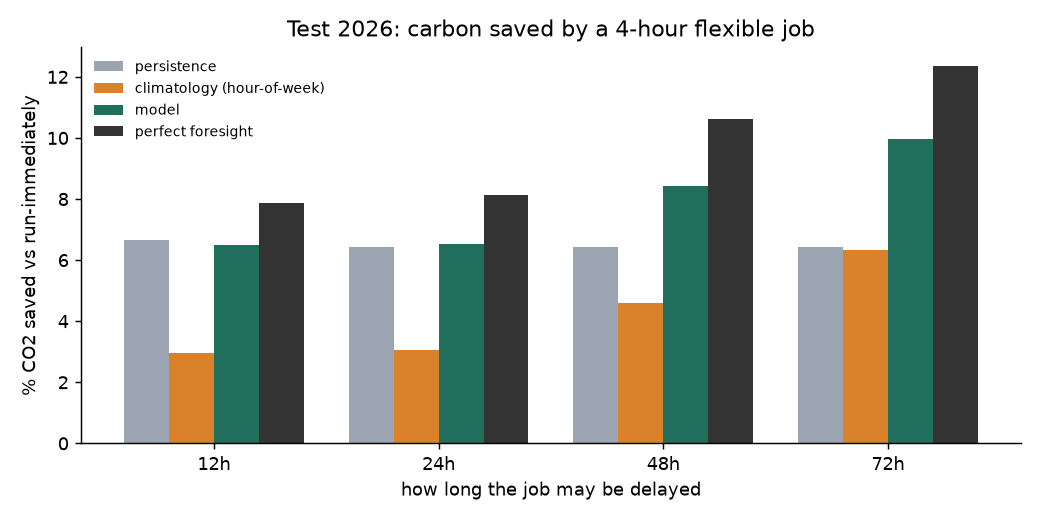

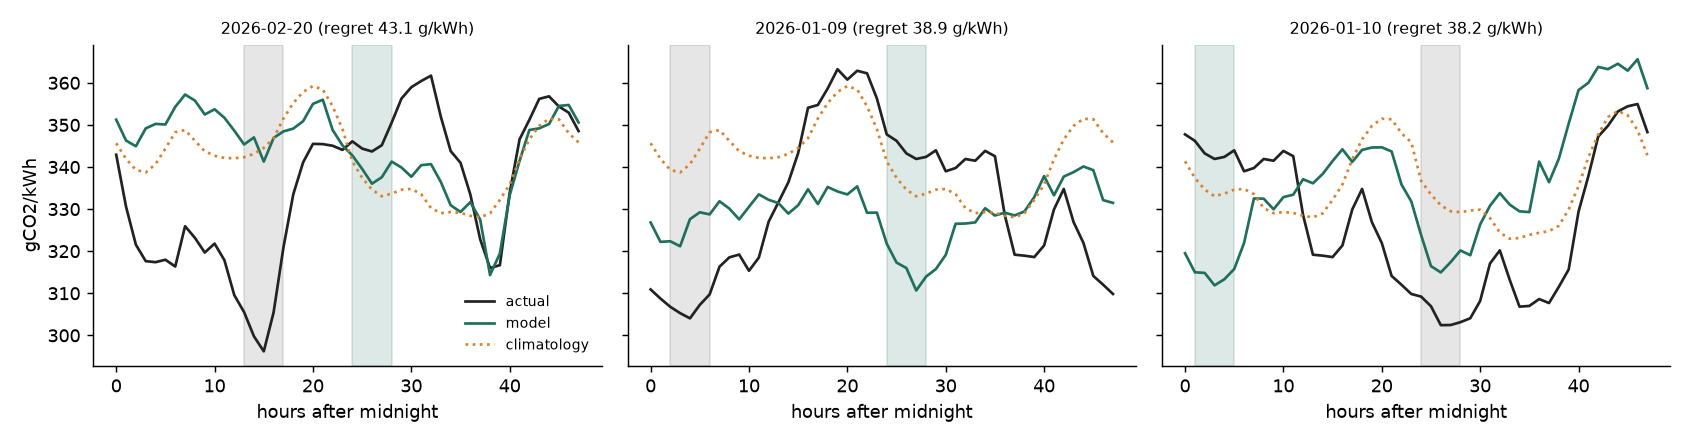

In [6]:
display(Image("results/savings_by_slip.png")); display(Image("results/failure_days.png"))

## 5. Where it fails
Figure above: green band = model's chosen window, grey band = best possible window. The three worst days at 24 h slip are 2026-02-20 and 2026-01-09 (the model chose the start of the next day, which turned out dirtier than the best window) and 2026-01-10 (it chose hour 1 when hour 24 was cleaner). Two of the three are back to back. Forecast error on those days was 16.6-21.7 g/kWh vs 13.8 average. Failures cluster in time (shifts in the generation mix after 18:00 that no input can see), not in weather extremes (about 6-8 C, ordinary wind).
Also: weekends (model beats climatology by just 1.1 g/kWh), and the 'unsure' rule gave no measurable gain.

## 6. Demo example (the Gradio app in `app/app.py` does this interactively)

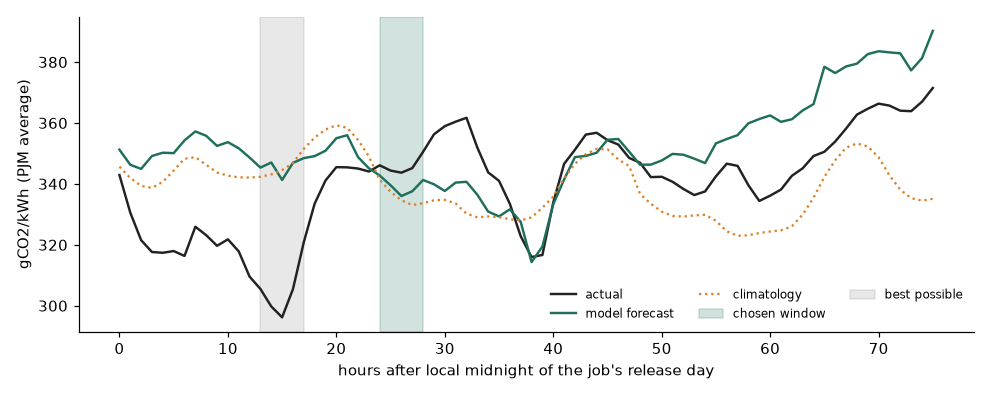

In [7]:
display(Image("results/demo_example.png"))